# Historical drought exposure map

Pick a **state**, **crop**, **drought definition** and **map measure**; the county map updates.

**What this map shows.** It describes what *already happened* in 2000–2025. It is **historical exposure**, not a forecast and not a risk estimate ("at risk").

**Drought definitions.** `max_drought_severity` in the master dataset is the worst U.S. Drought Monitor category reached in any week of the growing season (more than 1% of the county affected). The scale is offset by 1 from USDM's own labels:

| Definition | `max_drought_severity` | USDM label |
|---|---|---|
| D1+ moderate or worse | ≥ 2 | D1–D4 |
| D2+ severe or worse | ≥ 3 | D2–D4 |
| D3+ extreme or worse | ≥ 4 | D3–D4 |
| D4 exceptional | = 5 | D4 |

A county-year counts as a **drought year** when its season maximum reaches the chosen level.

**Map measures.**
- *Drought exposure*: number of drought years per county (hover shows the share of observed years).
- *Drought-year losses*: mean `yield_anomaly_pct` over that county's drought years that have a reported yield. Negative = below the county's own trend. Counties with no drought year that has a yield are left blank (blank is not zero).


In [1]:
import sys
sys.path.insert(0, "..")   # this notebook lives in notebooks/, src/ is one level up

import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display

from src.data_loader import load_master, load_counties

df = load_master()
counties = load_counties()   # GeoJSON, feature id = fips
print(f"{len(df):,} rows loaded")

17,056 rows loaded


In [2]:
# Dropdown options: label shown -> value used in the data
STATES = {
    "Iowa": "IA",
    "Nebraska": "NE",
    "California": "CA",
    "Delaware": "DE",
}
CROPS = {
    "Corn (grain)": "CORN",
    "Soybeans": "SOYBEANS",
    "Winter wheat": "WHEAT",
    "Grain sorghum": "SORGHUM",
}
# max_drought_severity is offset by 1 from USDM labels: 2 = D1, 3 = D2, 4 = D3, 5 = D4
DROUGHT_DEFS = {
    "D1+ moderate or worse (severity ≥ 2)": 2,
    "D2+ severe or worse (severity ≥ 3)": 3,
    "D3+ extreme or worse (severity ≥ 4)": 4,
    "D4 exceptional (severity = 5)": 5,
}
MEASURES = {
    "Drought exposure (number of drought years)": "exposure",
    "Drought-year losses (mean yield anomaly)": "loss",
}

In [3]:
def county_table(state, crop, threshold):
    """One row per county for the chosen state, crop and drought definition."""
    sub = df[(df["state_alpha"] == state) & (df["crop"] == crop)].copy()

    # Drop rows without drought data (e.g. wheat 2000, whose season starts before the
    # Drought Monitor archive does). NaN is not "no drought".
    sub = sub[sub["max_drought_severity"].notna()]
    sub["is_drought"] = sub["max_drought_severity"] >= threshold

    # Exposure: how many seasons reached the chosen drought level
    out = (
        sub.groupby(["fips", "county_name"], as_index=False)
        .agg(years_observed=("year", "nunique"),
             drought_years=("is_drought", "sum"))
    )
    out["pct_years_in_drought"] = 100 * out["drought_years"] / out["years_observed"]

    # Losses: yield anomaly in those drought years, only where a yield (and trend) exists
    dy = sub[sub["is_drought"] & sub["yield_anomaly_pct"].notna()]
    loss = (
        dy.groupby("fips", as_index=False)
        .agg(mean_yield_anomaly_pct=("yield_anomaly_pct", "mean"),
             worst_yield_anomaly_pct=("yield_anomaly_pct", "min"),
             drought_years_with_yield=("year", "nunique"))
    )
    return out.merge(loss, on="fips", how="left")

In [4]:
def make_map(state_label, crop_label, def_label, measure):
    state, crop, threshold = STATES[state_label], CROPS[crop_label], DROUGHT_DEFS[def_label]
    tbl = county_table(state, crop, threshold)

    if tbl.empty:
        return None, f"No data for {crop_label} in {state_label} (that crop is not grown there in this dataset)."

    base_hover = {
        "fips": False,
        "drought_years": True,
        "years_observed": True,
        "pct_years_in_drought": ":.0f",
        "drought_years_with_yield": True,
        "mean_yield_anomaly_pct": ":.1f",
    }
    labels = {
        "drought_years": "Drought years",
        "years_observed": "Years observed",
        "pct_years_in_drought": "% of years in drought",
        "drought_years_with_yield": "Drought years with yield",
        "mean_yield_anomaly_pct": "Mean yield anomaly (%)",
    }
    title_core = f"{state_label} {crop_label}: {def_label}, 2000–2025"

    if measure == "exposure":
        plot_df = tbl
        fig = px.choropleth(
            plot_df, geojson=counties, locations="fips",
            color="drought_years", color_continuous_scale="YlOrRd",
            range_color=(0, max(1, int(plot_df["drought_years"].max()))),
            hover_name="county_name", hover_data=base_hover, labels=labels,
            title=f"Historical drought exposure<br><sup>{title_core}</sup>",
        )
        fig.update_layout(coloraxis_colorbar_title="Drought<br>years")
        note = f"{len(plot_df)} counties shown. Counts seasons that reached the chosen drought level."
    else:
        plot_df = tbl.dropna(subset=["mean_yield_anomaly_pct"])
        if plot_df.empty:
            return None, ("No county has a drought year with a reported yield under this definition. "
                          "Try a milder drought definition.")
        fig = px.choropleth(
            plot_df, geojson=counties, locations="fips",
            color="mean_yield_anomaly_pct", color_continuous_scale="RdYlGn",
            range_color=(-40, 40),
            hover_name="county_name", hover_data=base_hover, labels=labels,
            title=f"Historical drought-year losses<br><sup>{title_core}</sup>",
        )
        fig.update_layout(coloraxis_colorbar_title="Mean yield<br>anomaly (%)")
        thin = int((plot_df["drought_years_with_yield"] <= 2).sum())
        note = (f"{len(plot_df)} of {len(tbl)} counties shown (blank = no drought year with a reported yield, "
                f"not zero loss). {thin} shown counties rest on 1-2 drought years, so treat them as noisy.")

    fig.update_geos(fitbounds="locations", visible=False)
    fig.update_layout(margin=dict(l=0, r=0, t=70, b=0), height=560)
    return fig, note

In [5]:
state_dd   = widgets.Dropdown(options=list(STATES),       value="Iowa",  description="State:",   layout=widgets.Layout(width="260px"))
crop_dd    = widgets.Dropdown(options=list(CROPS),        value="Corn (grain)", description="Crop:", layout=widgets.Layout(width="260px"))
def_dd     = widgets.Dropdown(options=list(DROUGHT_DEFS), value="D2+ severe or worse (severity ≥ 3)",
                              description="Drought:", layout=widgets.Layout(width="420px"))
measure_dd = widgets.Dropdown(options=[(k, v) for k, v in MEASURES.items()], value="exposure",
                              description="Map shows:", layout=widgets.Layout(width="420px"))
out = widgets.Output()

def refresh(_=None):
    with out:
        out.clear_output(wait=True)
        fig, note = make_map(state_dd.value, crop_dd.value, def_dd.value, measure_dd.value)
        if fig is not None:
            fig.show()
        print(note)
        print("Historical exposure, 2000–2025. Not a forecast; not a risk estimate.")

for w in (state_dd, crop_dd, def_dd, measure_dd):
    w.observe(refresh, names="value")

display(widgets.VBox([widgets.HBox([state_dd, crop_dd]), widgets.HBox([def_dd, measure_dd]), out]))
refresh()

# Evidence Found

We found no consistent evidence that higher soil water storage is associated with smaller yield losses during D2+ drought across the analyzed state-crop combinations.

The following code demonstrates that.

In [6]:
print("Total rows:", len(df))

print("\nUsable yield anomaly:")
print(df["yield_anomaly_pct"].notna().sum())

print("\nMissing yield anomaly:")
print(df["yield_anomaly_pct"].isna().sum())

print("\nUsable rows by state:")
print(
    df.groupby("state_alpha")["yield_anomaly_pct"]
      .apply(lambda x: x.notna().sum())
)

print("\nUsable rows by state and crop:")
print(
    df.groupby(["state_alpha", "crop"])["yield_anomaly_pct"]
      .apply(lambda x: x.notna().sum())
)

Total rows: 17056

Usable yield anomaly:
10995

Missing yield anomaly:
6061

Usable rows by state:
state_alpha
CA     514
DE     180
IA    4907
NE    5394
Name: yield_anomaly_pct, dtype: int64

Usable rows by state and crop:
state_alpha  crop    
CA           CORN         201
             SORGHUM        0
             WHEAT        313
DE           CORN          78
             SORGHUM        0
             SOYBEANS      72
             WHEAT         30
IA           CORN        2470
             SOYBEANS    2437
             WHEAT          0
NE           CORN        2058
             SORGHUM      433
             SOYBEANS    1709
             WHEAT       1194
Name: yield_anomaly_pct, dtype: int64


This data is important becuase not all columns have data (NaN), despite this, they are not zero. Therefore, they should still be considered.

The following table is a breakdown of the four states and their respective usable rows per crop.

In [10]:
analysis_df = df[
    df["yield_anomaly_pct"].notna() &
    (df["max_drought_severity"] > 3)
].copy()

print("\nDrought-year observations by state and crop:")
print(analysis_df.groupby(["state_alpha", "crop"]).size())


Drought-year observations by state and crop:
state_alpha  crop    
CA           CORN         29
             WHEAT        67
DE           CORN          3
             SOYBEANS      3
             WHEAT         5
IA           CORN        277
             SOYBEANS    317
NE           CORN        471
             SORGHUM     114
             SOYBEANS    397
             WHEAT       316
dtype: int64


In [11]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# STEP 1: Start with usable drought-year observations
# ---------------------------------------------------------
analysis_df = df[
    df["yield_anomaly_pct"].notna() &
    (df["max_drought_severity"] >= 3) &
    df["aws_100cm_mm"].notna()
].copy()


# ---------------------------------------------------------
# STEP 2: Get ONE soil-storage value per county/crop
# ---------------------------------------------------------
county_soil = (
    df[
        df["aws_100cm_mm"].notna()
    ][
        [
            "state_alpha",
            "crop",
            "fips",
            "county_name",
            "aws_100cm_mm"
        ]
    ]
    .drop_duplicates(
        subset=["state_alpha", "crop", "fips"]
    )
)


# ---------------------------------------------------------
# STEP 3: Find the median soil storage within each
# state + crop combination
# ---------------------------------------------------------
county_soil["soil_median"] = (
    county_soil
    .groupby(["state_alpha", "crop"])["aws_100cm_mm"]
    .transform("median")
)


# ---------------------------------------------------------
# STEP 4: Divide counties into High vs Low soil storage
# ---------------------------------------------------------
county_soil["soil_group"] = np.where(
    county_soil["aws_100cm_mm"] >= county_soil["soil_median"],
    "High",
    "Low"
)


# ---------------------------------------------------------
# STEP 5: Attach ONLY the soil group to drought data
# ---------------------------------------------------------
analysis_df = analysis_df.merge(
    county_soil[
        [
            "state_alpha",
            "crop",
            "fips",
            "soil_group"
        ]
    ],
    on=["state_alpha", "crop", "fips"],
    how="inner"
)


# ---------------------------------------------------------
# STEP 6: Average each county's yield anomaly across
# its D2+ drought years
# ---------------------------------------------------------
county_drought = (
    analysis_df
    .groupby(
        [
            "state_alpha",
            "crop",
            "fips",
            "soil_group"
        ],
        as_index=False
    )
    .agg(
        aws_100cm_mm=("aws_100cm_mm", "first"),
        drought_yield_anomaly=("yield_anomaly_pct", "mean"),
        drought_years=("year", "nunique")
    )
)


# ---------------------------------------------------------
# STEP 7: Count counties in each state/crop
# ---------------------------------------------------------
county_counts = (
    county_drought
    .groupby(["state_alpha", "crop"])["fips"]
    .nunique()
    .reset_index(name="county_count")
)

valid_combinations = county_counts[
    county_counts["county_count"] >= 10
][
    ["state_alpha", "crop"]
]


county_drought = county_drought.merge(
    valid_combinations,
    on=["state_alpha", "crop"],
    how="inner"
)


# ---------------------------------------------------------
# STEP 8: Calculate average drought loss for High vs Low
# ---------------------------------------------------------
results = (
    county_drought
    .groupby(
        ["state_alpha", "crop", "soil_group"]
    )
    .agg(
        counties=("fips", "nunique"),
        avg_drought_yield_anomaly=(
            "drought_yield_anomaly",
            "mean"
        )
    )
    .reset_index()
)


# ---------------------------------------------------------
# STEP 9: Put High and Low side-by-side
# ---------------------------------------------------------
comparison = results.pivot_table(
    index=["state_alpha", "crop"],
    columns="soil_group",
    values=[
        "counties",
        "avg_drought_yield_anomaly"
    ]
)

comparison.columns = [
    f"{col[1].lower()}_{col[0]}"
    for col in comparison.columns
]

comparison = comparison.reset_index()


# ---------------------------------------------------------
# STEP 10: Calculate High - Low
# ---------------------------------------------------------
comparison["high_minus_low"] = (
    comparison["high_avg_drought_yield_anomaly"]
    -
    comparison["low_avg_drought_yield_anomaly"]
)


print("HIGH vs LOW SOIL STORAGE DURING D2+ DROUGHT")
print("=" * 70)
print(comparison.round(2).to_string(index=False))

HIGH vs LOW SOIL STORAGE DURING D2+ DROUGHT
state_alpha     crop  high_avg_drought_yield_anomaly  low_avg_drought_yield_anomaly  high_counties  low_counties  high_minus_low
         CA     CORN                           -1.52                           2.34            7.0           6.0           -3.86
         CA    WHEAT                            2.27                           0.73           11.0           8.0            1.54
         IA     CORN                           -6.39                          -5.68           50.0          49.0           -0.71
         IA SOYBEANS                           -5.40                          -6.11           50.0          49.0            0.71
         NE     CORN                           -7.90                          -3.78           46.0          43.0           -4.12
         NE  SORGHUM                          -12.47                         -14.15           22.0           8.0            1.68
         NE SOYBEANS                           -7.21 

The following code then provides the bootstrap estimates:

In [12]:
import numpy as np

def bootstrap_difference(data, n_boot=2000, random_state=42):
    rng = np.random.default_rng(random_state)

    high = data[data["soil_group"] == "High"]["drought_yield_anomaly"].dropna().values
    low = data[data["soil_group"] == "Low"]["drought_yield_anomaly"].dropna().values

    if len(high) < 2 or len(low) < 2:
        return np.nan, np.nan, np.nan

    differences = []

    for _ in range(n_boot):
        high_sample = rng.choice(
            high,
            size=len(high),
            replace=True
        )

        low_sample = rng.choice(
            low,
            size=len(low),
            replace=True
        )

        differences.append(
            high_sample.mean() - low_sample.mean()
        )

    differences = np.array(differences)

    return (
        differences.mean(),
        np.percentile(differences, 2.5),
        np.percentile(differences, 97.5)
    )


bootstrap_results = []

for (state, crop), group in county_drought.groupby(
    ["state_alpha", "crop"]
):
    estimate, lower, upper = bootstrap_difference(group)

    bootstrap_results.append({
        "state_alpha": state,
        "crop": crop,
        "estimate": estimate,
        "lower_95": lower,
        "upper_95": upper
    })


bootstrap_results = pd.DataFrame(bootstrap_results)

print("BOOTSTRAP ESTIMATES")
print("=" * 70)
print(bootstrap_results.round(2).to_string(index=False))

BOOTSTRAP ESTIMATES
state_alpha     crop  estimate  lower_95  upper_95
         CA     CORN     -3.87     -7.40     -0.41
         CA    WHEAT      1.53     -1.12      4.36
         IA     CORN     -0.72     -1.79      0.42
         IA SOYBEANS      0.71     -0.68      2.09
         NE     CORN     -4.13     -6.55     -1.64
         NE  SORGHUM      1.69     -2.90      6.16
         NE SOYBEANS     -1.11     -3.39      1.30
         NE    WHEAT      0.19     -4.04      4.45


## Iowa corn (−0.72, range −1.79 to 0.42) and Iowa soybeans (+0.71, range −0.68 to 2.09) show no clear effect. Iowa is rainfed, so it is the cleanest case.

## Evidence: Soil water storage does not show a consistent drought-protection effect

**What the evidence does not say:** These results do **not** show that higher soil water storage causes greater or smaller yield losses. For most state-crop combinations, the uncertainty range includes zero, so the data do not provide clear evidence of a difference. The analysis also does not account for all potential factors, such as irrigation and crop productivity.

In [13]:
scope = (
    df[df["yield_anomaly_pct"].notna() & (df["max_drought_severity"] >= 3)]
    .groupby(["state_alpha", "crop"])
    .agg(counties=("fips", "nunique"),
         drought_county_years=("fips", "size"),
         first_year=("year", "min"), last_year=("year", "max"))
    .reset_index()
)
scope

,state_alpha,crop,counties,drought_county_years,first_year,last_year
0,CA,CORN,13,66,2001,2022
1,CA,WHEAT,19,153,2001,2023
2,DE,CORN,3,10,2002,2022
3,DE,SOYBEANS,3,13,2002,2024
4,DE,WHEAT,3,8,2002,2008
5,IA,CORN,99,762,2000,2024
6,IA,SOYBEANS,99,836,2000,2024
7,NE,CORN,89,878,2000,2025
8,NE,SORGHUM,30,196,2000,2025
9,NE,SOYBEANS,76,764,2000,2025


Mark which state-crop pairs are dropped (Delaware, for example) and why.

In [14]:
import statsmodels.formula.api as smf

panel = df[df["max_drought_severity"].notna() & df["yield_anomaly_pct"].notna()
           & df["aws_100cm_mm"].notna() & df["nccpi_crop"].notna()].copy()
panel["drought"] = (panel["max_drought_severity"] >= 3).astype(int)   # D2+
panel["aws_25"] = panel["aws_100cm_mm"] / 25

def soil_effect(d):
    m = smf.ols(
        "yield_anomaly_pct ~ drought + aws_25 + drought:aws_25 + nccpi_crop + C(year)",
        data=d,
    ).fit(cov_type="cluster", cov_kwds={"groups": d["fips"]})
    est = m.params["drought:aws_25"]
    lo, hi = m.conf_int().loc["drought:aws_25"]
    verdict = ("no clear effect" if lo <= 0 <= hi
               else "higher storage = smaller loss" if est > 0
               else "higher storage = LARGER loss")
    return pd.Series({"effect_pp_per_25mm": est, "lower_95": lo, "upper_95": hi,
                      "n_rows": len(d), "n_counties": d["fips"].nunique(),
                      "verdict": verdict})

effects = (panel.groupby(["state_alpha", "crop"])
                .filter(lambda g: g["fips"].nunique() >= 10)
                .groupby(["state_alpha", "crop"]).apply(soil_effect).reset_index())
effects

,state_alpha,crop,effect_pp_per_25mm,lower_95,upper_95,n_rows,n_counties,verdict
0,CA,CORN,-3.246039,-8.382505,1.890427,201,13,no clear effect
1,CA,WHEAT,-1.012521,-6.018754,3.993711,294,19,no clear effect
2,IA,CORN,-1.395748,-3.292340,0.500844,2470,99,no clear effect
3,IA,SOYBEANS,0.287112,-1.528273,2.102497,2437,99,no clear effect
4,NE,CORN,-2.123975,-2.847626,-1.400324,2058,89,higher storage = LARGER loss
5,NE,SORGHUM,-1.372315,-9.302198,6.557569,433,30,no clear effect
6,NE,SOYBEANS,-2.163157,-3.370040,-0.956275,1709,76,higher storage = LARGER loss
7,NE,WHEAT,-0.302748,-2.441399,1.835902,1135,60,no clear effect


In [15]:
from src.data_loader import load_irrigation
irr = load_irrigation().drop(columns=["state_alpha"])
ne = panel[panel.state_alpha == "NE"].merge(irr, on=["fips", "crop", "year"], how="left")
ne_dry = ne[ne["irrigated_share"] < 0.10]   # mostly-dryland county-years only

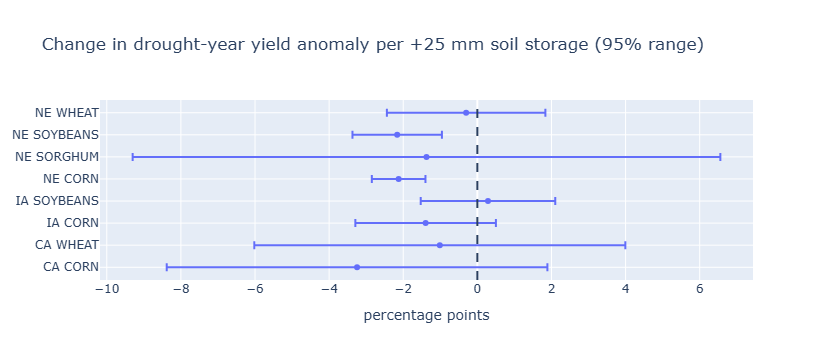

In [16]:
import plotly.graph_objects as go
effects["label"] = effects["state_alpha"] + " " + effects["crop"]
fig = go.Figure(go.Scatter(
    x=effects["effect_pp_per_25mm"], y=effects["label"], mode="markers",
    error_x=dict(type="data", symmetric=False,
                 array=effects["upper_95"] - effects["effect_pp_per_25mm"],
                 arrayminus=effects["effect_pp_per_25mm"] - effects["lower_95"])))
fig.add_vline(x=0, line_dash="dash")
fig.update_layout(title="Change in drought-year yield anomaly per +25 mm soil storage (95% range)",
                  xaxis_title="percentage points")
fig.show()

In [17]:
def build_priority(state, crop, years, threshold=3, k=3):
    d = df[(df.state_alpha == state) & (df.crop == crop) & df.year.isin(years)
           & df.max_drought_severity.notna()].copy()
    d["is_drought"] = d.max_drought_severity >= threshold
    g = (d.groupby(["fips", "county_name"], as_index=False)
           .agg(years_obs=("year", "nunique"), drought_years=("is_drought", "sum"),
                avg_acres=("acres_harvested", "mean"), avg_yield=("yield_per_acre", "mean")))
    dy = d[d.is_drought & d.yield_anomaly_pct.notna()]
    loss = (dy.groupby("fips").agg(raw_loss=("yield_anomaly_pct", "mean"),
                                   n_loss=("year", "nunique")).reset_index())
    g = g.merge(loss, on="fips", how="left")
    g["n_loss"] = g["n_loss"].fillna(0)
    prior = dy["yield_anomaly_pct"].mean()
    g["loss_pct"] = (g.n_loss * g.raw_loss.fillna(0) + k * prior) / (g.n_loss + k)
    g["freq"] = g.drought_years / g.years_obs
    g["expected_loss_bu"] = (g.freq * (-g.loss_pct).clip(lower=0) / 100
                             * g.avg_yield * g.avg_acres)
    g["priority_rank"] = g["expected_loss_bu"].rank(ascending=False, method="min")
    g["priority_flag"] = g["priority_rank"] <= max(1, round(0.2 * len(g)))   # top 20%
    return g.sort_values("priority_rank")


In [18]:
train, test = range(2000, 2013), range(2013, 2026)
pri = build_priority("IA", "CORN", train)

d = df[(df.state_alpha == "IA") & (df.crop == "CORN") & df.year.isin(test)
       & (df.max_drought_severity >= 3) & df.yield_anomaly_pct.notna()]
test_loss = d.groupby("fips")["yield_anomaly_pct"].mean().rename("test_loss").reset_index()
chk = pri.merge(test_loss, on="fips")

print("Spearman (priority score vs later loss):",
      chk["expected_loss_bu"].corr(-chk["test_loss"], method="spearman").round(2))
print("Later loss, flagged vs not:",
      chk.groupby("priority_flag")["test_loss"].mean().round(2).to_dict())

Spearman (priority score vs later loss): 0.27
Later loss, flagged vs not: {False: -2.47, True: -3.95}


to improve priority map: how often it had drought × how much yield it lost when it did × how many acres it has

implement priority to map

In [19]:
pri

,fips,county_name,years_obs,drought_years,avg_acres,avg_yield,raw_loss,n_loss,loss_pct,freq,expected_loss_bu,priority_rank,priority_flag
74,19149,Plymouth County,13,4,219330.769231,159.815385,-20.612500,4,-15.497673,0.307692,1.671480e+06,1.0,True
83,19167,Sioux County,13,5,229484.615385,173.253846,-9.766000,5,-9.357964,0.384615,1.431016e+06,2.0,True
77,19155,Pottawattamie County,13,5,226692.307692,159.761538,-9.444000,5,-9.156714,0.384615,1.275485e+06,3.0,True
23,19047,Crawford County,13,4,190207.692308,163.884615,-14.220000,4,-11.844815,0.307692,1.136086e+06,4.0,True
96,19193,Woodbury County,13,4,201215.384615,155.184615,-13.445000,4,-11.401958,0.307692,1.095484e+06,5.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,19135,Monroe County,13,6,26384.615385,131.746154,-9.533333,6,-9.248190,0.461538,1.483725e+05,95.0,False
19,19039,Clarke County,13,4,31792.307692,124.284615,-8.170000,4,-8.387673,0.307692,1.019759e+05,96.0,False
26,19053,Decatur County,13,4,30030.769231,132.023077,-7.470000,4,-7.987673,0.307692,9.744357e+04,97.0,False
3,19007,Appanoose County,13,5,28923.076923,127.330769,-4.682000,5,-6.180464,0.384615,8.754383e+04,98.0,False


In [21]:
def make_map(state_label, crop_label, def_label, measure):
    state, crop, threshold = STATES[state_label], CROPS[crop_label], DROUGHT_DEFS[def_label]
    tbl = county_table(state, crop, threshold)

    if tbl.empty:
        return None, f"No data for {crop_label} in {state_label} (that crop is not grown there in this dataset)."

    base_hover = {
        "fips": False,
        "drought_years": True,
        "years_observed": True,
        "pct_years_in_drought": ":.0f",
        "drought_years_with_yield": True,
        "mean_yield_anomaly_pct": ":.1f",
    }
    labels = {
        "drought_years": "Drought years",
        "years_observed": "Years observed",
        "pct_years_in_drought": "% of years in drought",
        "drought_years_with_yield": "Drought years with yield",
        "mean_yield_anomaly_pct": "Mean yield anomaly (%)",
    }
    title_core = f"{state_label} {crop_label}: {def_label}, 2000–2025"

    if measure == "exposure":
        plot_df = tbl
        fig = px.choropleth(
            plot_df, geojson=counties, locations="fips",
            color="drought_years", color_continuous_scale="YlOrRd",
            range_color=(0, max(1, int(plot_df["drought_years"].max()))),
            hover_name="county_name", hover_data=base_hover, labels=labels,
            title=f"Historical drought exposure<br><sup>{title_core}</sup>",
        )
        fig.update_layout(coloraxis_colorbar_title="Drought<br>years")
        note = f"{len(plot_df)} counties shown. Counts seasons that reached the chosen drought level."
    else:
        plot_df = tbl.dropna(subset=["mean_yield_anomaly_pct"])
        if plot_df.empty:
            return None, ("No county has a drought year with a reported yield under this definition. "
                          "Try a milder drought definition.")
        fig = px.choropleth(
            plot_df, geojson=counties, locations="fips",
            color="mean_yield_anomaly_pct", color_continuous_scale="RdYlGn",
            range_color=(-40, 40),
            hover_name="county_name", hover_data=base_hover, labels=labels,
            title=f"Historical drought-year losses<br><sup>{title_core}</sup>",
        )
        fig.update_layout(coloraxis_colorbar_title="Mean yield<br>anomaly (%)")
        thin = int((plot_df["drought_years_with_yield"] <= 2).sum())
        note = (f"{len(plot_df)} of {len(tbl)} counties shown (blank = no drought year with a reported yield, "
                f"not zero loss). {thin} shown counties rest on 1-2 drought years, so treat them as noisy.")

    fig.update_geos(fitbounds="locations", visible=False)
    fig.update_layout(margin=dict(l=0, r=0, t=70, b=0), height=560)
    return fig, note

state_dd   = widgets.Dropdown(options=list(STATES),       value="Iowa",  description="State:",   layout=widgets.Layout(width="260px"))
crop_dd    = widgets.Dropdown(options=list(CROPS),        value="Corn (grain)", description="Crop:", layout=widgets.Layout(width="260px"))
def_dd     = widgets.Dropdown(options=list(DROUGHT_DEFS), value="D2+ severe or worse (severity ≥ 3)",
                              description="Drought:", layout=widgets.Layout(width="420px"))
measure_dd = widgets.Dropdown(options=[(k, v) for k, v in MEASURES.items()], value="exposure",
                              description="Map shows:", layout=widgets.Layout(width="420px"))
out = widgets.Output()

def refresh(_=None):
    with out:
        out.clear_output(wait=True)
        fig, note = make_map(state_dd.value, crop_dd.value, def_dd.value, measure_dd.value)
        if fig is not None:
            fig.show()
        print(note)
        print("Historical exposure, 2000–2025. Not a forecast; not a risk estimate.")

for w in (state_dd, crop_dd, def_dd, measure_dd):
    w.observe(refresh, names="value")

display(widgets.VBox([widgets.HBox([state_dd, crop_dd]), widgets.HBox([def_dd, measure_dd]), out]))
refresh()